# Bayesian model comparison for mixture models

In this notebook we explore using Bayesian model comparison for mixture models. We evaluate both marginal likelihood-based approaches, as well as our [anchored reversible-jump SMC algorithm](https://arxiv.org/abs/2610.09930v1). 

In [24]:
%load_ext autoreload
%autoreload 2

import os

SELECTED_DEVICE = '6'
print(f'Setting CUDA visible devices to [{SELECTED_DEVICE}]')
os.environ['CUDA_VISIBLE_DEVICES'] = f'{SELECTED_DEVICE}'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Setting CUDA visible devices to [6]


In [25]:
import matplotlib.pyplot as plt

import jax
jax.config.update("jax_enable_x64", True)

import jax.random as jrnd
import jax.numpy as jnp
import blackjax

import sys
import pandas as pd

import numpyro.distributions as dist
import bamojax
from bamojax.base import Model
from bamojax.samplers import mcmc_sampler
from bamojax.inference import SMCInference
from bamojax.model_search.anchored_rjsmc import RJSMCInference, get_model_samples


from jax.scipy.special import logsumexp

print('Python version:     ', sys.version)
print('Jax version:        ', jax.__version__)
print('BlackJax version:   ', blackjax.__version__)
print('bamojax version:    ', bamojax.__version__)
print('Jax default backend:', jax.default_backend())
print('Jax devices:        ', jax.devices())

SMALL_SIZE = 12
MEDIUM_SIZE = 14
BIGGER_SIZE = 16

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=MEDIUM_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

def pretty_axis(ax, fix_xaxis=True, fix_yaxis=True):
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False) 
    if fix_xaxis:
        ax.spines['bottom'].set_position(('axes', -0.05))
    if fix_yaxis:
        ax.spines['left'].set_position(('axes', -0.05))

#

Python version:      3.11.15 (main, Mar  3 2026, 09:26:23) [GCC 11.4.0]
Jax version:         0.10.2
BlackJax version:    1.7.1
bamojax version:     0.4.4+1.g7233aed.dirty
Jax default backend: gpu
Jax devices:         [CudaDevice(id=0)]


## Data generation

First, let's generate some data that come from a 2D mixture model:

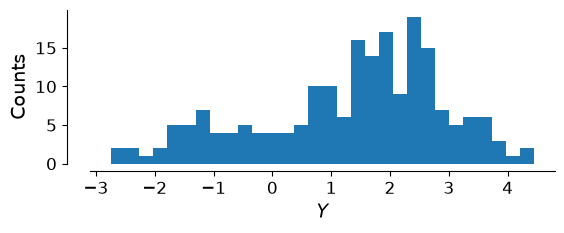

In [26]:
key = jrnd.PRNGKey(0)
key, subkey = jrnd.split(key)

n = 200

mu = jnp.asarray([-1.0, 2.0])
sigma = jnp.asarray([1.0, 1.0])
w = jnp.asarray([0.3, 0.7])

mixing_dist = dist.Categorical(probs=w)
component_dist = dist.Normal(loc=mu, scale=sigma)
mixture = dist.MixtureSameFamily(mixing_distribution=mixing_dist, component_distribution=component_dist)

Y = mixture.sample(subkey, sample_shape=(n, ))

plt.figure(figsize=(6, 2))
ax = plt.gca()
ax.hist(Y, bins=30)
ax.set_xlabel(r'$Y$')
ax.set_ylabel('Counts')
pretty_axis(ax)

Define models and inference functions:

In [27]:
def centered_softmax(x):
    return jax.nn.softmax(jnp.insert(x, 0, 0, axis=0)) 

#
def make_mixture_model(y, K):
    def mm_link_fn(w, mu, sigma):
        mu = jnp.sort(mu)
        probs = centered_softmax(w)
        return dict(mixing_distribution=dist.Categorical(probs=probs),
                    component_distribution=dist.Normal(mu, sigma))

    #

    model = Model(f'Model with {K} component(s)')
    w_node = model.add_node('w', distribution=dist.Normal(0, 1), shape=(K-1, ))
    mu_node = model.add_node('mu', distribution=dist.Normal(0, 1), shape=(K, ))
    sigma_node = model.add_node('sigma', distribution=dist.Gamma(concentration=2, rate=1), shape=(K, ))
    obs_node = model.add_node('Y', distribution=dist.MixtureSameFamily, parents=dict(w=w_node, mu=mu_node, sigma=sigma_node), link_fn=mm_link_fn, observations=y, shape=(1, ))
    return model

#
def smc_fit(key, model, num_particles = 1000, num_mutations = 3, num_chains = 1, mutator = blackjax.hmc):
    engine = SMCInference(model=model, num_particles=num_particles, num_mutations=num_mutations, num_chains=num_chains, mcmc_kernel=mcmc_sampler(model, mutator), adaptive=True)
    return jax.jit(engine.run)(key)

#
num_particles = 1000

models = [make_mixture_model(Y, K=K) for K in [1, 2, 3]]
M = len(models)

We approximate the posterior and marginal likelihood using sequential Monte Carlo, using adaptive Hamiltonian Monte Carlo mutations:

In [28]:
%%time

fits = []

for model in models:
    key, subkey = jrnd.split(key)
    res = smc_fit(subkey, model)
    fits.append(res)

lmls = jnp.asarray([res['lml'] for res in fits])

pmps = jnp.exp(lmls - logsumexp(lmls))
print(jnp.round(pmps, 2))

[0.   0.67 0.33]
CPU times: user 8.68 s, sys: 494 ms, total: 9.17 s
Wall time: 8.91 s


Let's see what these models predict:

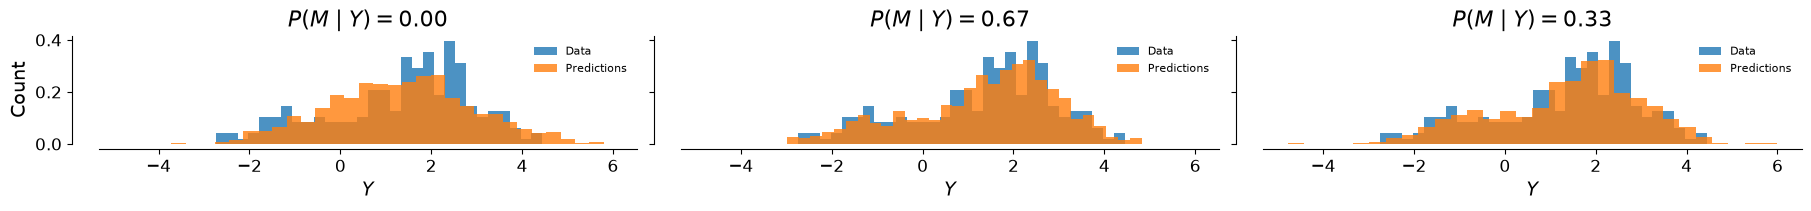

In [29]:
def get_predictions(key, model, samples, n_pred):
    keys = jrnd.split(key, n_pred)
    preds = jax.vmap(model.sample_posterior_predictive)(keys, samples)
    return preds['Y']

#
_, axes = plt.subplots(nrows=1, ncols=M, sharex=True, sharey=True, constrained_layout=True, figsize=(18, 2))
for model, fit, ax, pmp in zip(models, fits, axes, pmps):
    key, subkey = jrnd.split(key)
    particles = fit['final_state'].particles
    preds = get_predictions(subkey, model, particles, num_particles)
    ax.hist(Y, bins=30, density=True, alpha=0.8, label='Data')
    ax.hist(preds, bins=30, density=True, alpha=0.8, label='Predictions')
    ax.set_title(f'$P(M \mid Y) = {pmp:0.2f}$')
    ax.set_xlabel(r'$Y$')
    ax.legend(frameon=False, fontsize=8)
    pretty_axis(ax)
axes[0].set_ylabel('Count');

## Anchored reversible-jump SMC

Now we do the same with ARJSMC. Recall that typically this involves manually constructing jump proposals, but our approach uses SMC together with kernel density estimation to avoid this laborious task.

In [30]:
%%time
num_particles = 5000
kernels = [dict(mcmc_kernel=blackjax.normal_random_walk, mcmc_parameters=dict(sigma=0.15 * jnp.eye(int(m.get_model_size())))) for m in models]

engine = RJSMCInference(models, num_particles=num_particles, within_model_kernels=kernels, num_mutations=100)
key, subkey = jrnd.split(key)
arjsmc_res = engine.run(subkey)
print(jnp.round(arjsmc_res['model_probs'], 2))

[0.   0.65 0.35]
CPU times: user 11.5 s, sys: 215 ms, total: 11.7 s
Wall time: 11.6 s


The result is practically identical! 

/home/maxhin/Documents/Repos/bamojax/.venv/lib/python3.11/site-packages/numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges


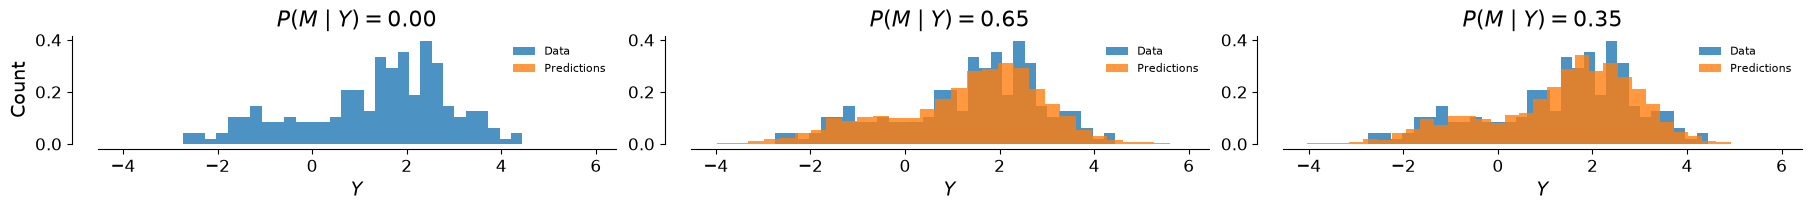

In [31]:
arjsmc_fits = [get_model_samples(arjsmc_res, i) for i in range(len(models))]

_, axes = plt.subplots(nrows=1, ncols=M, sharex=True, constrained_layout=True, figsize=(18, 2))
for model, particles, ax, pmp in zip(models, arjsmc_fits, axes, arjsmc_res['model_probs']):
    key, subkey = jrnd.split(key)
    n_model = particles['mu'].shape[0]
    preds = get_predictions(subkey, model, particles, n_model)
    ax.hist(Y, bins=30, density=True, alpha=0.8, label='Data')
    ax.hist(preds, bins=30, density=True, alpha=0.8, label='Predictions')
    ax.set_title(f'$P(M \mid Y) = {pmp:0.2f}$')
    ax.set_xlabel(r'$Y$')
    ax.legend(frameon=False, fontsize=8)
    pretty_axis(ax)
axes[0].set_ylabel('Count');

The result for the models with $K>1$ look similar to the ones we saw when fitting these models in isolation. Because the model probability for $K=1$ is approximately zero, no particles have this model as the active model - hence we cannot show its approximation. This is the same for RJMCMC algorithms.